# Ejercicio 05 · Recomendador de películas reproducible

**INF-8239 · Ciencia de Datos II · Unidad 03 (LAB08 y LAB09)**
Estudiante: Emma Carolina Cabrera Valverde

Este notebook no entrena modelos: lee los archivos que los scripts dejaron en `reports/` y el dataset descargado en `data/raw/`. Para regenerar los resultados se ejecutan los comandos del `README.md` en orden.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REP, DATA = ROOT / "reports", ROOT / "data" / "raw" / "ml-latest-small"
pd.set_option("display.max_colwidth", 60)
print("reports/ existe:", REP.exists(), "· datos descargados:", DATA.exists())

reports/ existe: True · datos descargados: True


## 1. Auditoría de MovieLens Latest Small

In [2]:
ratings = pd.read_csv(DATA / "ratings.csv")
movies = pd.read_csv(DATA / "movies.csv")
por_usuario = ratings.groupby("userId").size()
auditoria = pd.Series({
    "Usuarios": ratings["userId"].nunique(),
    "Películas en catálogo": movies["movieId"].nunique(),
    "Películas valoradas": ratings["movieId"].nunique(),
    "Valoraciones": len(ratings),
    "Densidad (%)": round(100 * len(ratings) / (ratings["userId"].nunique() * ratings["movieId"].nunique()), 2),
    "Rating medio": round(ratings["rating"].mean(), 4),
    "Valoraciones por usuario (mín.)": por_usuario.min(),
    "Valoraciones por usuario (máx.)": por_usuario.max(),
})
auditoria.astype(object).to_frame("valor")

,valor
Usuarios,610.0
Películas en catálogo,9742.0
Películas valoradas,9724.0
Valoraciones,100836.0
Densidad (%),1.7
Rating medio,3.5016
Valoraciones por usuario (mín.),20.0
Valoraciones por usuario (máx.),2698.0


Solo 1.70 % de los pares usuario–película tiene una valoración. Lo que falta es desconocido, no un rechazo. Todas las personas tienen al menos 20 valoraciones, así que el conjunto no representa a quien usa poco la plataforma.

## 2. LAB08 · Popularidad suavizada

In [3]:
pop = pd.read_csv(REP / "popular_top10.csv")
pop[["title", "count", "mean", "weighted_score"]].round(3)

,title,count,mean,weighted_score
0,"Shawshank Redemption, The (1994)",317,4.429,4.395
1,"Godfather, The (1972)",192,4.289,4.243
2,Fight Club (1999),218,4.273,4.233
3,Star Wars: Episode IV - A New Hope (1977),251,4.231,4.198
4,"Usual Suspects, The (1995)",204,4.238,4.197
5,"Godfather: Part II, The (1974)",129,4.260,4.195
6,Schindler's List (1993),220,4.225,4.188
7,Goodfellas (1990),126,4.250,4.185
8,Dr. Strangelove or: How I Learned to Stop Worrying and L...,97,4.268,4.184
9,"Dark Knight, The (2008)",149,4.238,4.183


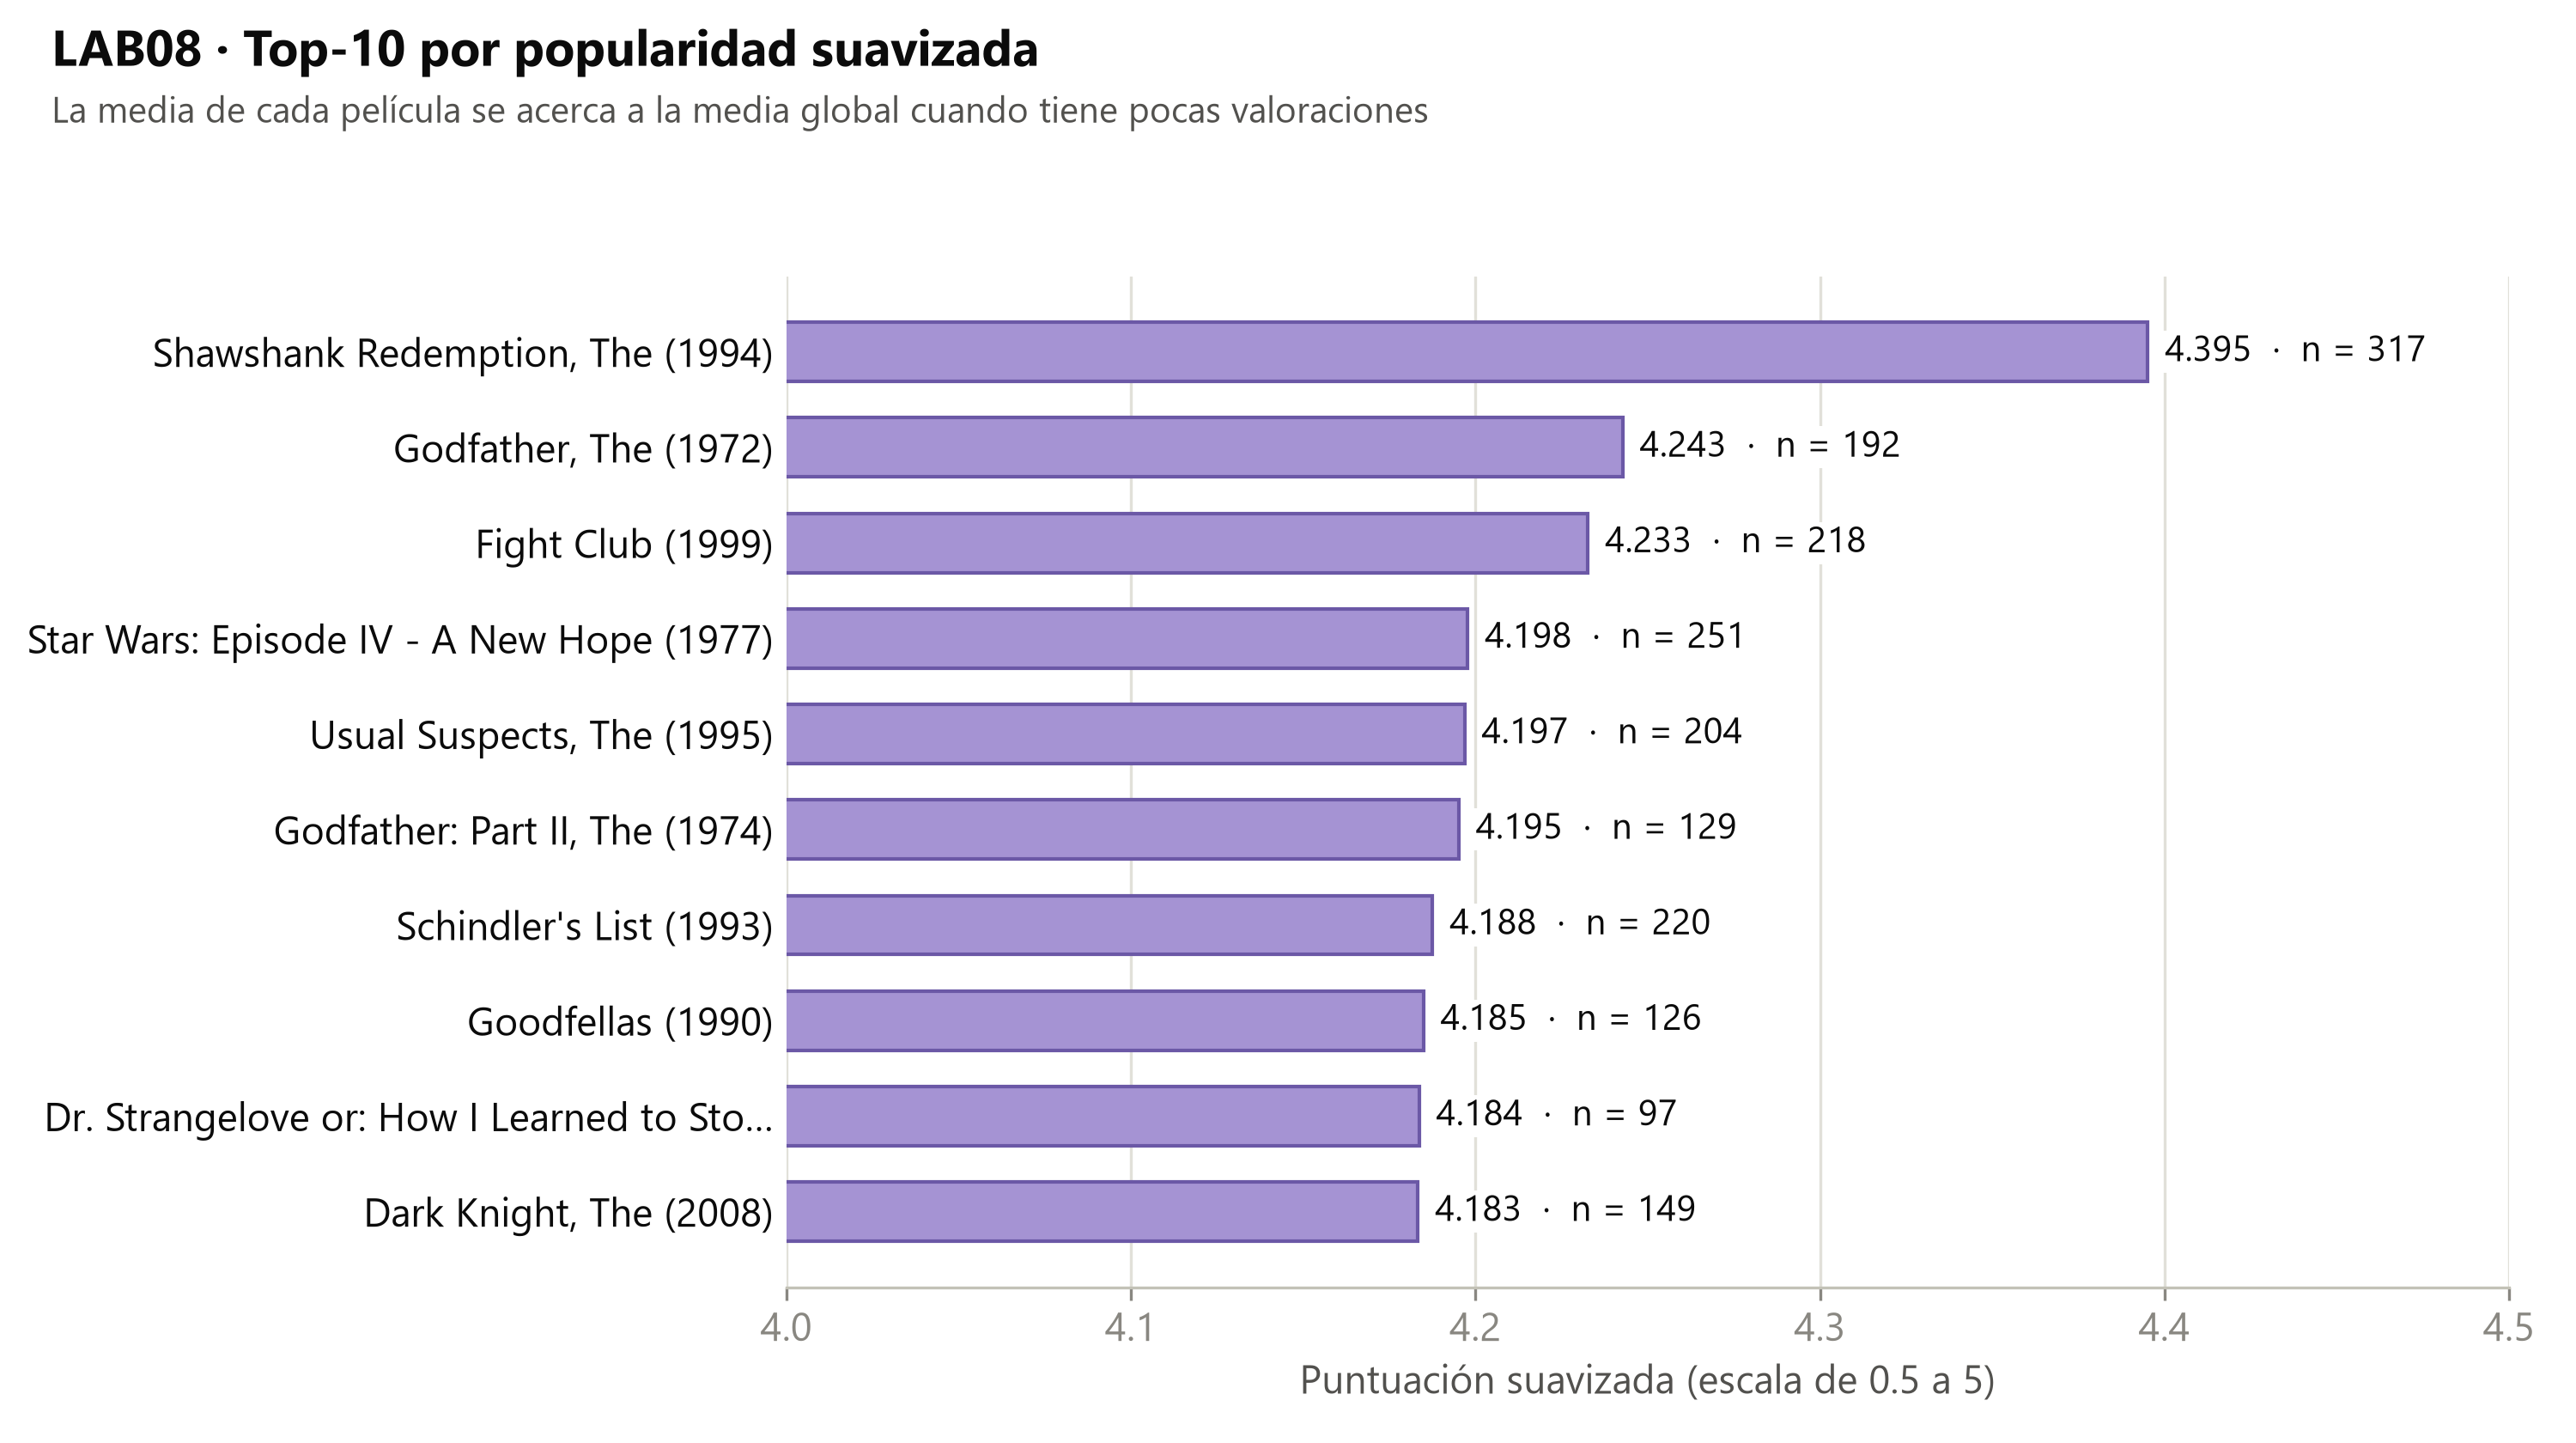

In [4]:
display(Image(REP / "graficos" / "lab08_popularidad_top10.png", width=760))

La puntuación suavizada acerca a la media global las películas con pocas valoraciones. Por eso *Dr. Strangelove* (97 valoraciones, media 4.27) queda por debajo de títulos con medias parecidas y más evidencia. Es la misma lista para todo el mundo: no es personalizada.

## 3. LAB08 · Recomendación por contenido (tres consultas)

In [5]:
consultas = {
    "amelie": "Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)",
    "alien": "Alien (1979)",
    "finding_nemo": "Finding Nemo (2003)",
}
resumen = []
for clave, titulo in consultas.items():
    lista = pd.read_csv(REP / f"content_{clave}.csv")
    resumen.append({
        "consulta": titulo,
        "géneros de la consulta": movies.loc[movies["title"].eq(titulo), "genres"].iloc[0],
        "se excluye a sí misma": titulo not in set(lista["title"]),
        "empates en el máximo": int((lista["content_score"].round(6) == lista["content_score"].round(6).max()).sum()),
        "ejemplos": ", ".join(lista["title"].head(3)),
    })
pd.DataFrame(resumen)

,consulta,géneros de la consulta,se excluye a sí misma,empates en el máximo,ejemplos
0,"Amelie (Fabuleux destin d'Amélie Poulain, Le) (2001)",Comedy|Romance,True,10,"Heartbreaker (L'Arnacoeur) (2010), Life as We Know It (2..."
1,Alien (1979),Horror|Sci-Fi,True,10,"Swamp Thing (1982), Village of the Damned (1995), Attack..."
2,Finding Nemo (2003),Adventure|Animation|Children|Comedy,True,10,"Nut Job, The (2014), American Tail, An (1986), Peanuts M..."


En las tres consultas los diez resultados tienen exactamente los mismos géneros que la película de partida (similitud 1.0) y quedan empatados; el orden entre ellos no tiene significado. La similitud mide coincidencia de géneros, no trama, calidad ni probabilidad de que la película guste. El riesgo es la sobre-especialización: quien consulta *Alien* solo ve terror y ciencia ficción.

## 4. LAB09 · Cuatro modelos con el mismo protocolo

In [6]:
protocolo = pd.read_csv(REP / "lab09_comparison_protocol.csv")
protocolo[["train_interactions", "test_interactions", "evaluable_interactions", "excluded_test_interactions", "factors", "epochs", "alpha", "seed"]]

,train_interactions,test_interactions,evaluable_interactions,excluded_test_interactions,factors,epochs,alpha,seed
0,100226,610,587,23,20,12,0.75,42


In [7]:
comp = pd.read_csv(REP / "lab09_models_comparison.csv")
tabla = comp[["modelo"]].copy()
tabla["HitRate@10 (%)"] = (comp["hit_rate_at_10"] * 100).round(2)
tabla["Cobertura (%)"] = (comp["catalog_coverage"] * 100).round(2)
tabla

,modelo,HitRate@10 (%),Cobertura (%)
0,popularidad,3.24,0.63
1,contenido,0.17,7.78
2,colaborativo,3.75,7.46
3,hibrido,3.07,9.70


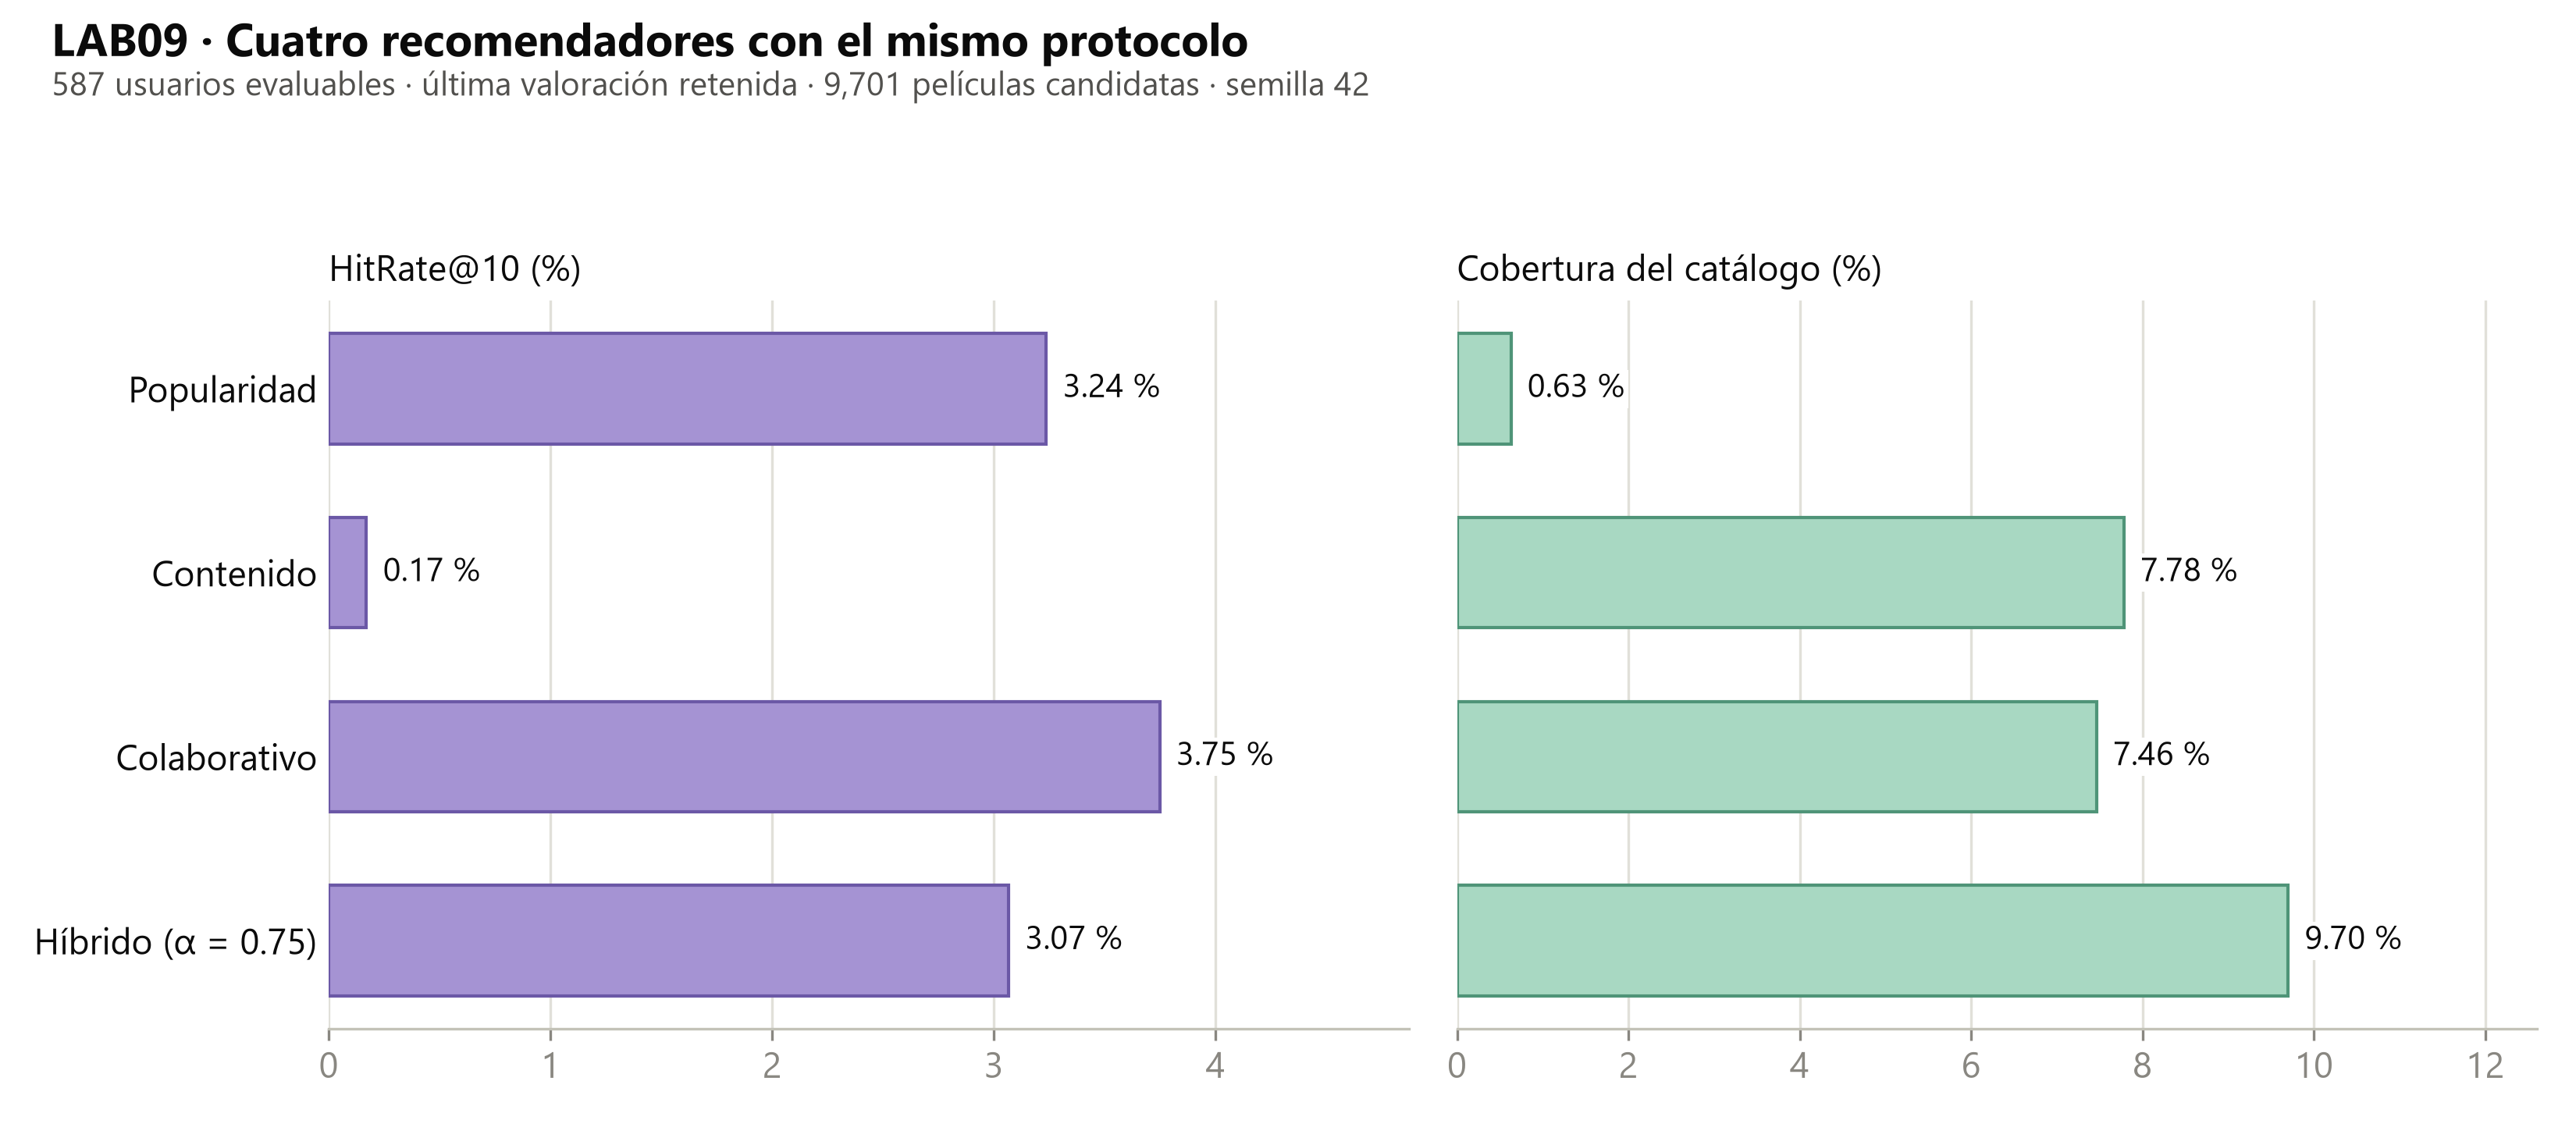

In [8]:
display(Image(REP / "graficos" / "lab09_comparacion_modelos.png", width=760))

El colaborativo acierta más (3.75 %), el híbrido cubre más catálogo (9.70 %) y la popularidad, con un HitRate parecido, concentra la exposición en 0.63 % de las películas. El contenido solo casi no recupera la película retenida (0.17 %).

## 5. LAB09 · Estabilidad del híbrido según α y semilla

In [9]:
res = pd.read_csv(REP / "lab09_results.csv")
res[["alpha", "seed", "rmse", "hit_rate_at_10", "catalog_coverage", "train_seconds"]].round(4)

,alpha,seed,rmse,hit_rate_at_10,catalog_coverage,train_seconds
0,0.25,42,1.0264,0.0324,0.1065,15.4846
1,0.25,123,1.0261,0.0221,0.0970,14.3618
2,0.25,2026,1.0242,0.0324,0.0980,14.3454
3,0.75,42,1.0264,0.0375,0.0775,14.4709
4,0.75,123,1.0261,0.0290,0.0699,16.0386
5,0.75,2026,1.0242,0.0290,0.0738,14.4863


In [10]:
resumen = pd.read_csv(REP / "lab09_summary.csv")
vista = pd.DataFrame({
    "α": resumen["alpha"],
    "corridas": resumen["corridas"],
    "RMSE": resumen["rmse_mean"].round(4),
    "HitRate@10 (%)": (resumen["hit_rate_at_10_mean"] * 100).round(2).astype(str) + " ± " + (resumen["hit_rate_at_10_std"] * 100).round(2).astype(str),
    "Cobertura (%)": (resumen["catalog_coverage_mean"] * 100).round(2).astype(str) + " ± " + (resumen["catalog_coverage_std"] * 100).round(2).astype(str),
    "Tiempo (s)": resumen["train_seconds_mean"].round(1),
})
vista

,α,corridas,RMSE,HitRate@10 (%),Cobertura (%),Tiempo (s)
0,0.25,3,1.0256,2.9 ± 0.59,10.05 ± 0.52,14.7
1,0.75,3,1.0256,3.18 ± 0.49,7.37 ± 0.38,15.0


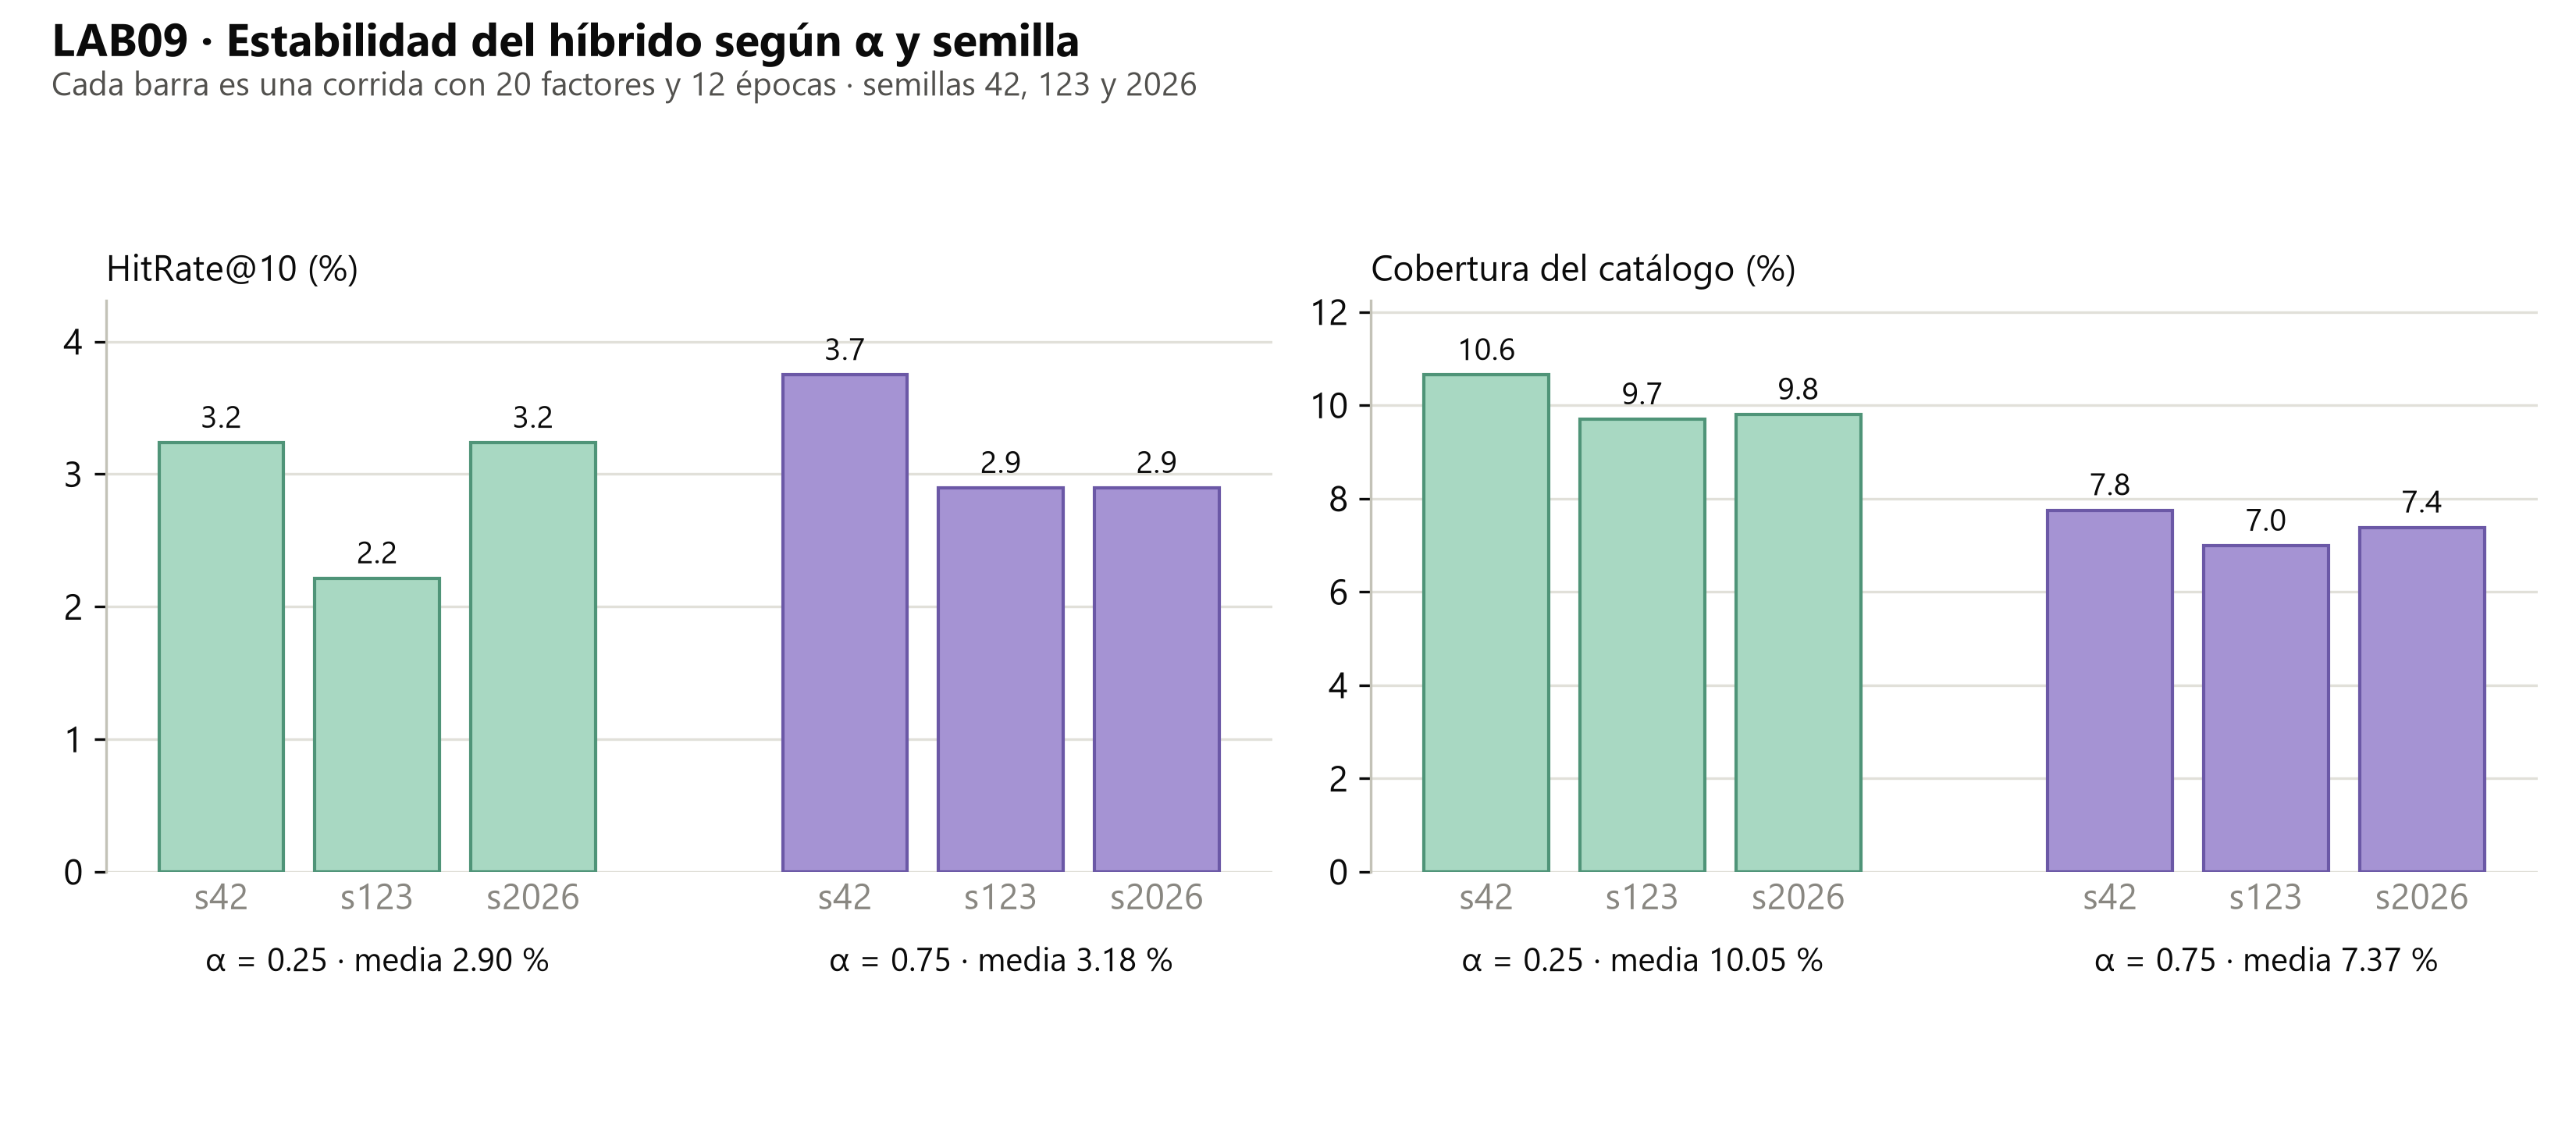

In [11]:
display(Image(REP / "graficos" / "lab09_alpha_semillas.png", width=760))

α no cambia el RMSE (la factorización es la misma), solo el orden del Top-10. Con α = 0.75 sube el HitRate; con α = 0.25 sube la cobertura. Ninguna domina a la otra.

## 6. LAB09 · Tres perfiles de usuario

In [12]:
perfiles = {p: pd.read_csv(REP / f"profile_{p}.csv") for p in ["historial_amplio", "historial_reducido", "usuario_nuevo"]}
populares = set(pop["movieId"])
pd.DataFrame([{
    "perfil": p,
    "usuario": int(df["userId"].iloc[0]),
    "valoraciones": int((ratings["userId"] == df["userId"].iloc[0]).sum()),
    "método": df["method"].iloc[0],
    "en Top-10 de popularidad": len(set(df["movieId"]) & populares),
} for p, df in perfiles.items()])

,perfil,usuario,valoraciones,método,en Top-10 de popularidad
0,historial_amplio,414,2698,collaborative,0
1,historial_reducido,595,20,collaborative,5
2,usuario_nuevo,999999,0,popularity_fallback,3


Con 20 valoraciones, la mitad de la lista del usuario 595 coincide con el Top-10 de popularidad: el modelo tiene poca información propia de esa persona. El usuario nuevo recibe el fallback, una lista explícitamente no personalizada.

## 7. Costo computacional y tabla de Pareto

In [13]:
costo = pd.read_csv(REP / "lab09_cost_summary.csv")
costo[["factors", "rmse", "total_parameters", "matrix_size_mib", "training_seconds"]].round(4)

,factors,rmse,total_parameters,matrix_size_mib,training_seconds
0,10,1.0337,103110,0.7867,14.8491
1,20,1.0264,206220,1.5733,15.0776
2,40,1.0211,412440,3.1467,14.8713


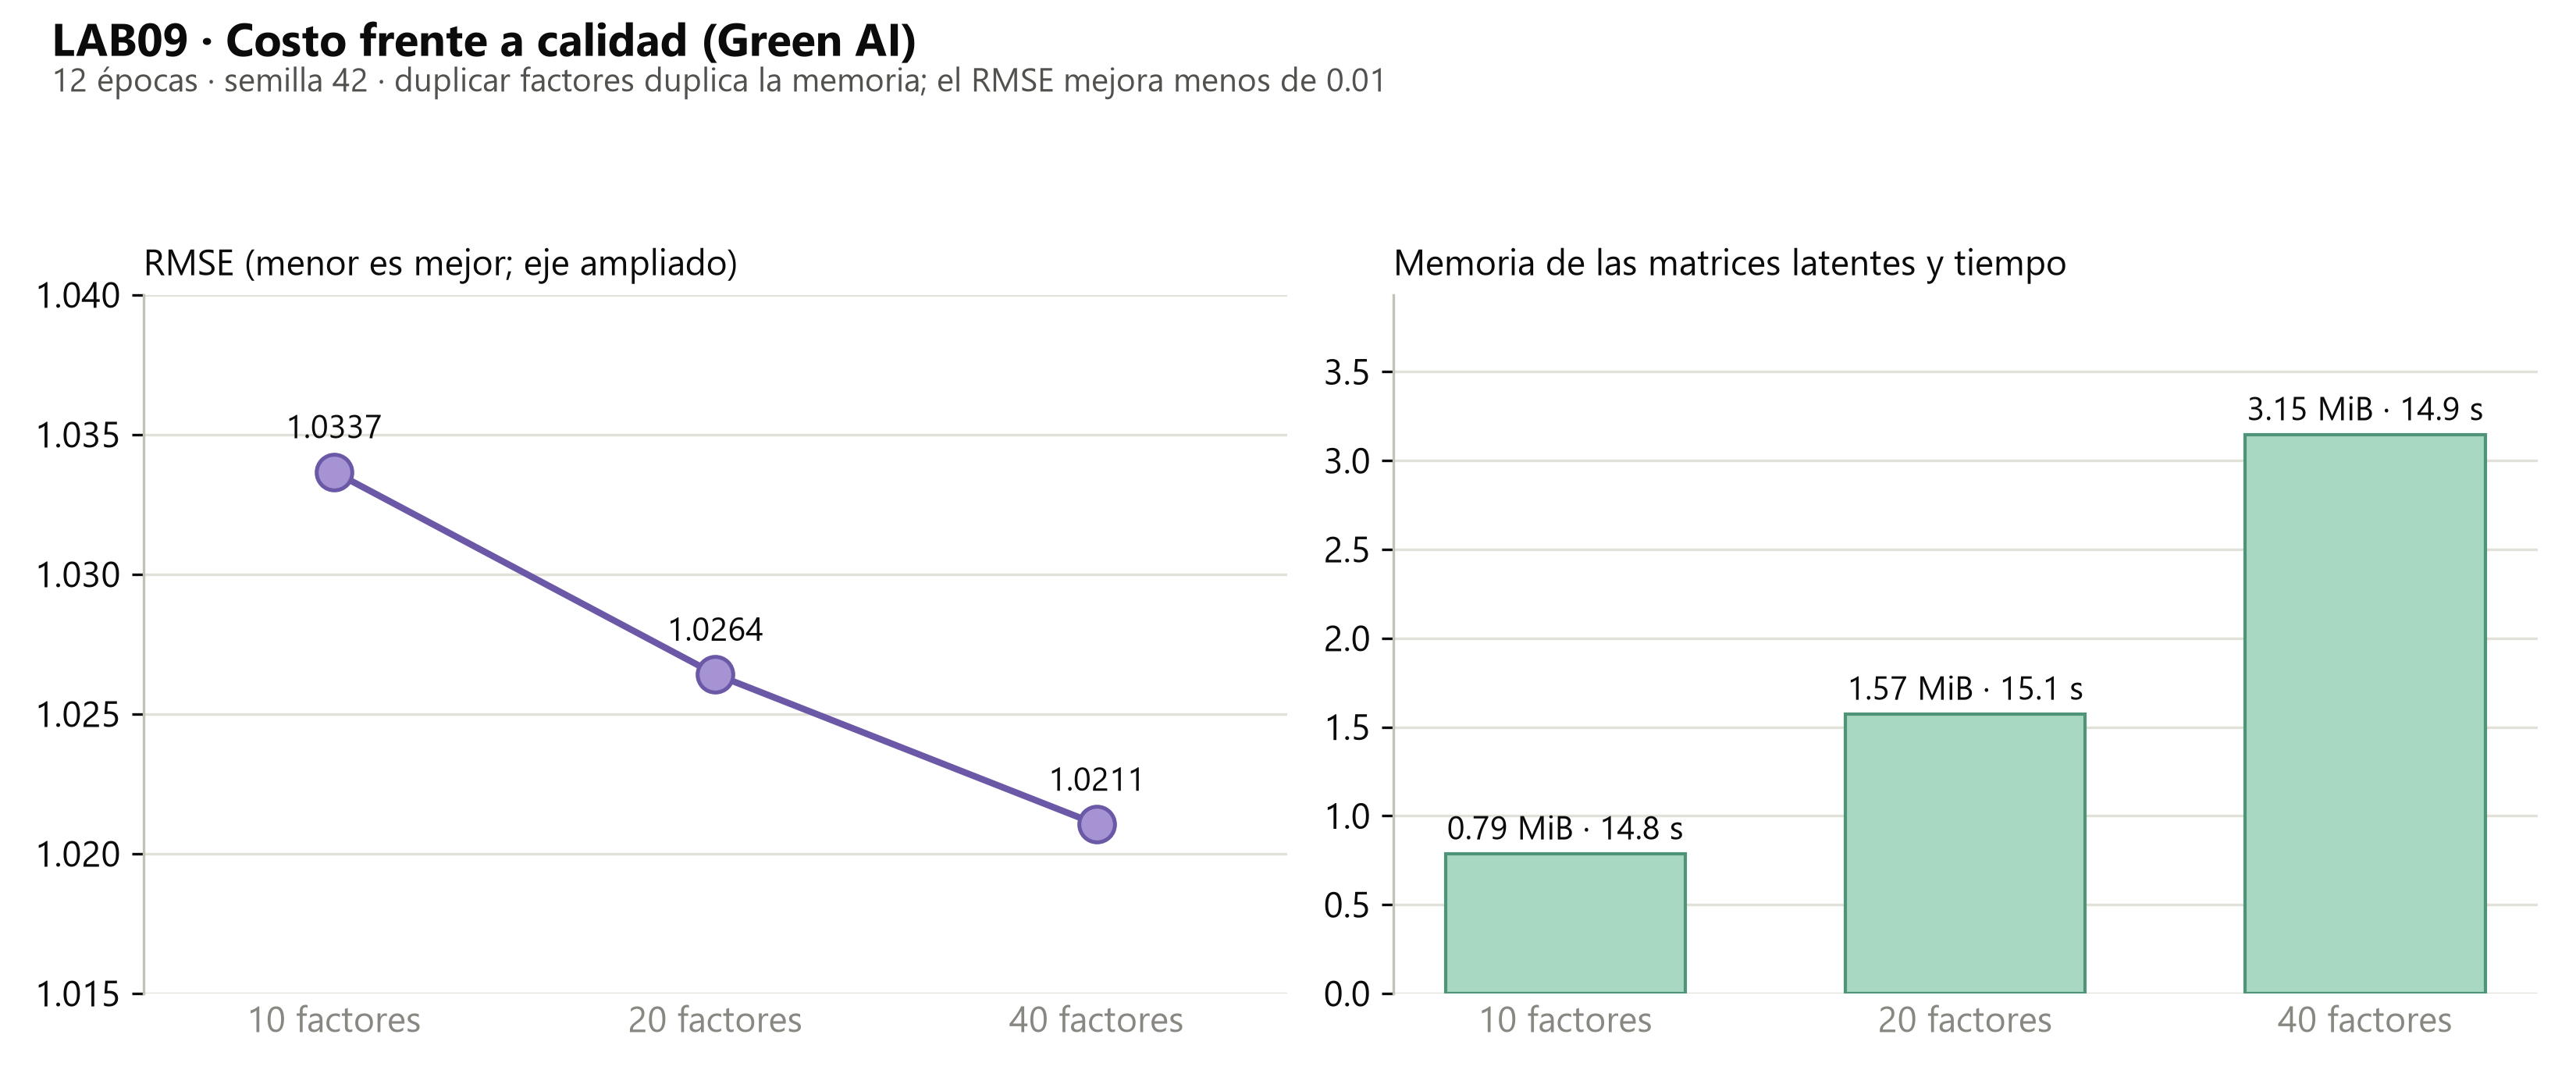

In [14]:
display(Image(REP / "graficos" / "lab09_costo_factores.png", width=760))

In [15]:
def dominada(fila, tabla):
    otras = tabla.drop(fila.name)
    return bool(((otras["rmse"] <= fila["rmse"]) & (otras["matrix_size_mib"] <= fila["matrix_size_mib"])
                 & ((otras["rmse"] < fila["rmse"]) | (otras["matrix_size_mib"] < fila["matrix_size_mib"]))).any())

costo["dominada (RMSE vs. memoria)"] = costo.apply(dominada, axis=1, tabla=costo)
costo[["factors", "rmse", "matrix_size_mib", "dominada (RMSE vs. memoria)"]].round(4)

,factors,rmse,matrix_size_mib,dominada (RMSE vs. memoria)
0,10,1.0337,0.7867,False
1,20,1.0264,1.5733,False
2,40,1.0211,3.1467,False


Ninguna configuración está dominada. Cada duplicación de factores duplica la memoria y mejora el RMSE menos de 0.01; el tiempo casi no cambia. Siguiendo el criterio Green AI, se mantienen 20 factores.

## 8. Conclusión

- **Ratings:** RMSE 1.0264 con 20 factores; 40 factores bajan a 1.0211 con el doble de memoria.
- **Ranking:** el colaborativo tiene el mejor HitRate@10 (3.75 %); el híbrido α = 0.75 queda cerca (3.07 %; 3.18 % de media en tres semillas).
- **Cobertura:** el híbrido muestra más catálogo (9.70 % con α = 0.75; 10.05 % de media con α = 0.25) que la popularidad (0.63 %).
- **Usuario frío:** recibe la lista de popularidad, declarada como no personalizada.
- **Decisión:** híbrido con 20 factores y α = 0.75, con fallback de popularidad. Es una decisión para un prototipo evaluado offline; no mide satisfacción real.
- **Riesgo principal:** concentración en títulos populares y burbuja de géneros. Mitigación: vigilar la cobertura en cada versión y pedir preferencias iniciales a quien llega nuevo.